# Significance Testing

This notebook tests whether each strategy from the strategy grid is profitable using a one-sided t-test on its daily returns. Since thousands of strategies are tested at once, many will appear significant by chance alone, which is measured here before any multiple testing corrections are applied.

The random strategies are regenerated with the same seed as in the previous notebook, so the results are identical.

In [1]:
# Importing the necessary packages and functions
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import stats
from functions import *

## Data

The in-sample data, buy-and-hold benchmark, and random strategy grid are regenerated exactly as in the previous notebook.

In [2]:
# Getting the required data
ticker, start_date, end_date = 'SPY', '2006-01-01', '2021-01-01'
SPY_data = get_data(ticker, start_date, end_date)

# Running the buy-and-hold benchmark
SPY_bh_positions = pd.Series(1.0, index=SPY_data.index)
SPY_bh_returns = strategy_returns(SPY_bh_positions, SPY_data['Open'], SPY_data['Close'])

# Regenerating the random strategy grid with the same seed
n_strategies, seed = 5000, 8162004
results_df, sample_returns = run_random_grid(ticker, SPY_data, n_strategies, seed)

[*********************100%***********************]  1 of 1 completed


## t-Tests

Each strategy is tested with a one-sided t-test, where the null hypothesis is that its mean daily return is 0 and the alternative is that it is positive. The t-statistic is equal to the annualized Sharpe ratio multiplied by the square root of the number of years, and the p-value is the probability of a t-statistic at least that large if the strategy had no skill.

In [3]:
# t-statistic and one-sided p-value for each strategy
n_days = len(SPY_bh_returns)
years = n_days / 252
results_df['t-stat'] = results_df['Sharpe'] * np.sqrt(years)
results_df['p-value'] = stats.t.sf(results_df['t-stat'], df=n_days - 1)

### Checking the t-Test

The t-statistic calculated from the Sharpe ratio is checked against scipy's built-in t-test, run directly on one strategy's daily returns.

In [4]:
# Checking the formula against scipy's t-test for one strategy
name, returns = next(iter(sample_returns.items()))
t_scipy, p_scipy = stats.ttest_1samp(returns, 0, alternative='greater')
print(f'{name}')
print(f'From Sharpe ratio: t = {results_df.loc[name, "t-stat"]:.4f}, p = {results_df.loc[name, "p-value"]:.4f}')
print(f'From scipy:        t = {t_scipy:.4f}, p = {p_scipy:.4f}')

SPY_Long_Short_0
From Sharpe ratio: t = 0.2815, p = 0.3892
From scipy:        t = 0.2815, p = 0.3892


## Uncorrected Results

Each strategy is treated as if it were the only one tested, and is counted as significant if its p-value is below 5%. Since none of the strategies have any skill, about 5% are expected to pass by chance, and every one that does is a false discovery. Buy-and-hold is shown for reference.

In [5]:
# Buy-and-hold t-test for reference
bh_t = sharpe_ratio(SPY_bh_returns) * np.sqrt(years)
bh_p = stats.t.sf(bh_t, df=n_days - 1)
print(f'Buy-and-hold: t = {bh_t:.4f}, p = {bh_p:.4f}')

# Strategies that look significant at the 5% level with no correction
alpha = 0.05
n_significant = (results_df['p-value'] < alpha).sum()
print(f'\nRandom strategies significant at 5%: {n_significant} of {len(results_df)} ({n_significant / len(results_df):.2%})')
print(f'Expected by chance: {alpha * len(results_df):.0f} of {len(results_df)}')

# Splitting the seemingly significant strategies by strategy
long_short_df = results_df[results_df.index.str.startswith(f'{ticker}_Long_Short')]
continuous_df = results_df[results_df.index.str.startswith(f'{ticker}_Continuous')]
long_short_significant = (long_short_df['p-value'] < alpha).sum()
continuous_significant = (continuous_df['p-value'] < alpha).sum()
print(f'Long/short: {long_short_significant} of {len(long_short_df)}')
print(f'Continuous: {continuous_significant} of {len(continuous_df)}')

Buy-and-hold: t = 2.1680, p = 0.0151

Random strategies significant at 5%: 511 of 10000 (5.11%)
Expected by chance: 500 of 10000
Long/short: 255 of 5000
Continuous: 256 of 5000


In [6]:
# Top 10 strategies by t-statistic
results_df.sort_values('t-stat', ascending=False).head(10).round(4)

,Ann. Return,Ann. Volatility,Sharpe,Max Drawdown,t-stat,p-value
SPY_Continuous_4520,0.1800,0.1514,1.1686,-0.3456,4.5234,0.0000
SPY_Long_Short_820,0.1656,0.1908,0.8986,-0.2822,3.4783,0.0003
SPY_Continuous_481,0.1233,0.1487,0.8566,-0.2549,3.3158,0.0005
SPY_Continuous_1087,0.1247,0.1507,0.8549,-0.3682,3.3093,0.0005
SPY_Continuous_589,0.1210,0.1462,0.8543,-0.2381,3.3068,0.0005
SPY_Long_Short_2994,0.1580,0.1959,0.8462,-0.3567,3.2756,0.0005
SPY_Long_Short_767,0.1492,0.1923,0.8193,-0.2735,3.1714,0.0008
SPY_Continuous_840,0.1152,0.1471,0.8144,-0.2577,3.1526,0.0008
SPY_Long_Short_1211,0.1494,0.1971,0.8046,-0.3167,3.1146,0.0009
SPY_Long_Short_2395,0.1456,0.1922,0.8024,-0.2722,3.1061,0.0010


### Distribution of p-Values

If none of the strategies have any skill, their p-values should be spread evenly between 0 and 1. The dashed line shows the number expected in each bin, and the first bin contains the strategies that look significant at the 5% level.

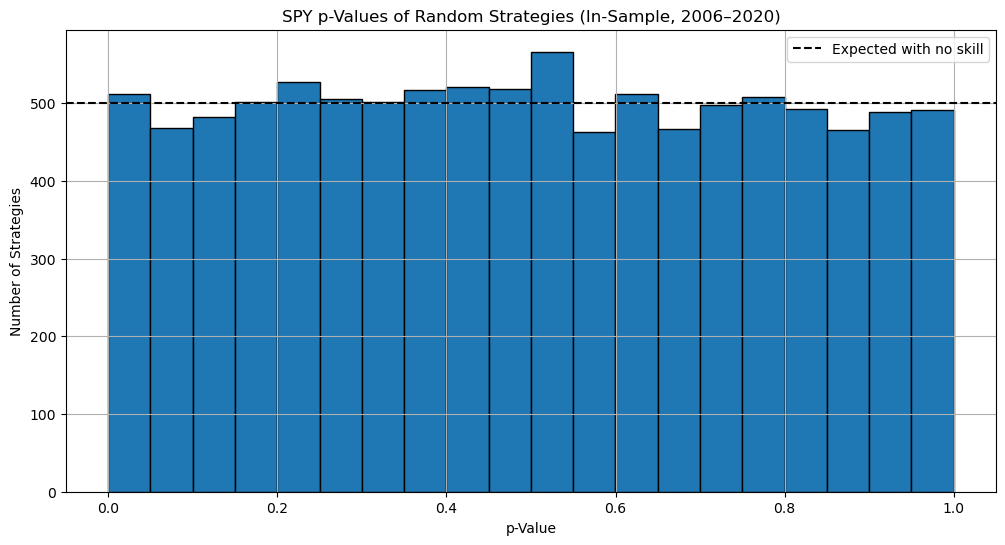

In [7]:
# Histogram of p-values with the count expected under no skill
plt.figure(figsize=(12, 6))
plt.hist(results_df['p-value'], bins=20, edgecolor='black')
plt.axhline(len(results_df) / 20, linestyle='--', color='black', label='Expected with no skill')
plt.title(f'{ticker} p-Values of Random Strategies (In-Sample, 2006–2020)')
plt.xlabel('p-Value')
plt.ylabel('Number of Strategies')
plt.legend()
plt.grid(True)
plt.show()